<div style="background:#080c10;padding:22px 26px;border-radius:10px;border-left:4px solid #00d4ff">
<h1 style="color:#00d4ff;margin:0 0 8px 0">NFL Opening &amp; Closing Odds, US Books — Verify before you buy</h1>
<p style="color:#e6edf3;margin:0;font-size:15px">The figures of the listing and of its README, recomputed from the file of the
full product: 2,377 NFL games from the 2018 season to week 10 of 2026, opening and closing prices from FanDuel, DraftKings,
BetMGM, Caesars, BetRivers, BetOnline, theScore, Fanatics, Hard Rock, Pinnacle, Bet365, Betcris, Kalshi and Polymarket, in
American odds, each with the time it was recorded.</p>
</div>

This notebook runs on the **full product**, not on the sample. Each section states a claim of the listing or of the
README, recomputes it from the file and prints **PASS** or **FAIL**. The expected values are written in plain sight in
the `CLAIMS` cell and next to the checks of the listing's images; everything else is read from the data. Only what the
file cannot show is not recomputed: the counts of prices left out while it was built.

🏈 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/yjnxja?utm_source=github&utm_medium=notebook&utm_campaign=nfl_us&utm_content=notebook_top)** · also on [Whop](https://whop.com/oliviersportsdata/nfl-opening-closing-odds-9-us-books-pinnacle-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nfl_us&utm_content=whop_top) · free 26-game sample: same layout, same 309 columns.

In [1]:
import os, glob, zipfile, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
NAME = "NFL_Opening_Closing_Odds_2018-2026"

def find_csv():
    """The CSV of the full product (the largest match wins: sample and full may both be attached), or the CSV inside the ZIP."""
    hits = []
    for base in (os.environ.get("NFL_ROOT", ""), "/kaggle/input", "."):
        if base and os.path.isdir(base):
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.csv"), recursive=True) if os.path.isfile(p)]
            hits += [p for p in glob.glob(os.path.join(base, "**", NAME + "*.zip"), recursive=True) if os.path.isfile(p)]
    if not hits:
        raise FileNotFoundError(NAME + ".csv not found: attach the full dataset to this notebook")
    return max(hits, key=os.path.getsize)

PATH = find_csv()
if PATH.endswith(".zip"):
    data = zipfile.ZipFile(PATH).read(NAME + ".csv")
    RAW = pd.read_csv(io.BytesIO(data), dtype=str, keep_default_na=False)
    F = pd.read_csv(io.BytesIO(data), low_memory=False)
else:
    RAW = pd.read_csv(PATH, dtype=str, keep_default_na=False)      # every cell exactly as written in the file
    F = pd.read_csv(PATH, low_memory=False)                          # the same file, numbers parsed
print(f"{os.path.basename(PATH)}  ·  {len(F):,} rows  ·  {F.shape[1]} columns")

RESULTS = []
def check(label, ok, detail=""):
    RESULTS.append((label, bool(ok)))
    print(("PASS  " if ok else "FAIL  ") + label + (f"   [{detail}]" if detail != "" else ""))

SOURCES = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore",
           "Fanatics", "HardRock", "Betcris", "Kalshi", "Polymarket"]
BOOKS = SOURCES[:12]
START = pd.to_datetime(RAW["Kickoff_UTC"])
def has(col): return RAW[col] != ""
def mins(col): return (pd.to_datetime(RAW[col].where(has(col))) - START).dt.total_seconds() / 60
def first_day(mask): return RAW.loc[mask, "Game_ID"].str[:8].min()
def any_close(s): return has(f"{s}_ML_Close_Time") | has(f"{s}_Spread_Close_Time") | has(f"{s}_Total_Close_Time")

NFL_Opening_Closing_Odds_2018-2026.csv  ·  2,377 rows  ·  309 columns


## The claims
The expected values, copied from the README in the ZIP and from the listing.

In [2]:
CLAIMS = {
    # README and listing: the file
    "games": 2377, "seasons": 9, "columns": 309, "prices": 212370,
    "first_day": "20180906", "last_day": "20261116", "games_2026": 150, "last_week_2026": 10,
    "stages": {"Regular Season": 2277, "Playoffs": 100}, "endings": {"Regulation": 2239, "Overtime": 138},
    "ties": 9, "neutral_site": 54, "super_bowls": 8,
    # listing: first closing / opening moneyline, source by source (US Eastern dates)
    "first_close_ml": {"Bet365": "20180906", "BetOnline": "20180906", "Betcris": "20180906", "FanDuel": "20181004",
                       "DraftKings": "20190203", "BetRivers": "20190905", "Pinnacle": "20200910", "Caesars": "20200910",
                       "BetMGM": "20200913", "theScore": "20231116", "HardRock": "20251026", "Kalshi": "20251116",
                       "Polymarket": "20260110", "Fanatics": "20261025"},
    "first_open_ml_prediction_markets": "20261022",
    # README "Said plainly" and listing "Read this before you buy"
    "bet365_total_first": "20191013", "bet365_january_2026_games": 28, "draftkings_games_2018_season": 1,
    "draftkings_open_ml_share_2023_2025": 15, "caesars_open_spread_share_2023_2025": 23,
    "closing_markets_2025": {"BetRivers": 1, "Fanatics": 6, "HardRock": 3},
    "betrivers_openings_before_2026": {"ML": 11, "Spread": 9, "Total": 61},
    "bet365_games_without_close_ml": 92,
    "betcris_last_day": "20261102", "kalshi_polymarket_same_close_2026": (97, 129),
    "team_totals_period": ("20210103", "20260208"), "open_without_close": 1336,
    # subscription listing: 2026 so far
    "min_close_ml_share_2026_core": 88,
    # README: median closing time of the moneyline, minutes against the scheduled kickoff (0 = at the start)
    "ml_close_median_min": {"Pinnacle": 0, "Bet365": -7, "FanDuel": -9, "DraftKings": -9, "BetMGM": -9, "Caesars": -9,
                            "BetRivers": -70, "BetOnline": -9, "theScore": -9, "Fanatics": 0, "HardRock": 0,
                            "Betcris": -7, "Kalshi": -9, "Polymarket": -1},
}

## 1. The file
Games, seasons, stages, endings, ties, neutral sites, columns and prices.

In [3]:
check("games", len(RAW) == CLAIMS["games"], len(RAW))
check("columns", RAW.shape[1] == CLAIMS["columns"], RAW.shape[1])
check("seasons", RAW["Season"].nunique() == CLAIMS["seasons"], sorted(RAW["Season"].unique()))
check("one row per game", RAW["Game_ID"].is_unique and RAW["NFL_Game_ID"].is_unique)
day = RAW["Game_ID"].str[:8]
check("first and last day (US Eastern)", (day.min(), day.max()) == (CLAIMS["first_day"], CLAIMS["last_day"]), (day.min(), day.max()))
y26 = RAW["Season"] == "2026"
check("2026 games, through week 10", y26.sum() == CLAIMS["games_2026"] and RAW.loc[y26, "Week"].astype(int).max() == CLAIMS["last_week_2026"])
check("stages", RAW["Stage"].value_counts().to_dict() == CLAIMS["stages"], RAW["Stage"].value_counts().to_dict())
check("endings", RAW["Match_Ending"].value_counts().to_dict() == CLAIMS["endings"], RAW["Match_Ending"].value_counts().to_dict())
check("ties", (RAW["Winner"] == "Tie").sum() == CLAIMS["ties"])
check("neutral-site games and Super Bowls", ((RAW["Neutral_Site"] == "Yes").sum(), (RAW["Week"] == "Super Bowl").sum()) == (CLAIMS["neutral_site"], CLAIMS["super_bowls"]))
price_cols = [c for c in RAW.columns if c.split("_")[0] in SOURCES and not c.endswith("_Time") and "_Line_" not in c]
n_prices = int((RAW[price_cols] != "").sum().sum())
check("prices", n_prices == CLAIMS["prices"], f"{n_prices:,}")
per_source = {s: sum(c.startswith(s + "_") for c in RAW.columns) for s in SOURCES}
check("22 columns per book, 38 for Pinnacle, 6 for Kalshi and Polymarket",
      per_source == {**{s: 22 for s in BOOKS}, "Pinnacle": 38, "Kalshi": 6, "Polymarket": 6}, per_source)

PASS  games   [2377]
PASS  columns   [309]
PASS  seasons   [['2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026']]
PASS  one row per game
PASS  first and last day (US Eastern)   [('20180906', '20261116')]
PASS  2026 games, through week 10
PASS  stages   [{'Regular Season': 2277, 'Playoffs': 100}]
PASS  endings   [{'Regulation': 2239, 'Overtime': 138}]
PASS  ties
PASS  neutral-site games and Super Bowls
PASS  prices   [212,370]
PASS  22 columns per book, 38 for Pinnacle, 6 for Kalshi and Polymarket   [{'Pinnacle': 38, 'Bet365': 22, 'FanDuel': 22, 'DraftKings': 22, 'BetMGM': 22, 'Caesars': 22, 'BetRivers': 22, 'BetOnline': 22, 'theScore': 22, 'Fanatics': 22, 'HardRock': 22, 'Betcris': 22, 'Kalshi': 6, 'Polymarket': 6}]


## 2. Scores
Final score, winner, total points, margin.

In [4]:
hs, aw = F["Home_Score"], F["Away_Score"]
check("Total_Score = home + away", (F["Total_Score"] == hs + aw).all())
check("Margin = |home - away|", (F["Margin"] == (hs - aw).abs()).all())
check("Winner follows the score, Tie when level", (F["Winner"] == np.where(hs > aw, "Home", np.where(aw > hs, "Away", "Tie"))).all())
check("every tie went to overtime", (F.loc[F["Winner"] == "Tie", "Match_Ending"] == "Overtime").all())

PASS  Total_Score = home + away
PASS  Margin = |home - away|
PASS  Winner follows the score, Tie when level
PASS  every tie went to overtime


## 3. Each source, from when
The first closing moneyline of each source, as the listing states them.

In [5]:
for s, d in CLAIMS["first_close_ml"].items():
    got = first_day(has(f"{s}_ML_Home_Close"))
    check(f"{s}: first closing moneyline {d}", got == d, got)
for s in ("Kalshi", "Polymarket"):
    got = first_day(has(f"{s}_ML_Home_Open"))
    check(f"{s}: first opening moneyline {CLAIMS['first_open_ml_prediction_markets']}", got == CLAIMS["first_open_ml_prediction_markets"], got)

PASS  Bet365: first closing moneyline 20180906   [20180906]
PASS  BetOnline: first closing moneyline 20180906   [20180906]
PASS  Betcris: first closing moneyline 20180906   [20180906]
PASS  FanDuel: first closing moneyline 20181004   [20181004]
PASS  DraftKings: first closing moneyline 20190203   [20190203]
PASS  BetRivers: first closing moneyline 20190905   [20190905]
PASS  Pinnacle: first closing moneyline 20200910   [20200910]
PASS  Caesars: first closing moneyline 20200910   [20200910]
PASS  BetMGM: first closing moneyline 20200913   [20200913]
PASS  theScore: first closing moneyline 20231116   [20231116]
PASS  HardRock: first closing moneyline 20251026   [20251026]
PASS  Kalshi: first closing moneyline 20251116   [20251116]
PASS  Polymarket: first closing moneyline 20260110   [20260110]
PASS  Fanatics: first closing moneyline 20261025   [20261025]
PASS  Kalshi: first opening moneyline 20261022   [20261022]
PASS  Polymarket: first opening moneyline 20261022   [20261022]


## 4. The gaps, said plainly
Every limit stated in the README and the listing, recomputed.

In [6]:
check("Pinnacle: no price before the 2020 season", not any_close("Pinnacle")[RAW["Season"] < "2020"].any())
check("Bet365: totals start on 13 October 2019", first_day(has("Bet365_Total_Line_Close") | has("Bet365_Total_Line_Open")) == CLAIMS["bet365_total_first"])
jan = RAW["Game_ID"].str[:6] == "202601"
b365 = [c for c in RAW.columns if c.startswith("Bet365_") and not c.endswith("_Time")]
check("Bet365: no price on the 28 games of January 2026", jan.sum() == CLAIMS["bet365_january_2026_games"] and not (RAW.loc[jan, b365] != "").any().any())
check("DraftKings: one game of the 2018 season, Super Bowl LIII",
      any_close("DraftKings")[RAW["Season"] == "2018"].sum() == CLAIMS["draftkings_games_2018_season"]
      and RAW.loc[any_close("DraftKings") & (RAW["Season"] == "2018"), "Week"].tolist() == ["Super Bowl"])
y2325 = RAW["Season"].isin(["2023", "2024", "2025"])
share = int(100 * has("DraftKings_ML_Home_Open")[y2325].mean())
check("DraftKings: opening moneyline on 15% of the 2023 to 2025 games", share == CLAIMS["draftkings_open_ml_share_2023_2025"], share)
share = int(100 * has("Caesars_Spread_Home_Open")[y2325].mean())
check("Caesars: opening spread on 23% of the 2023 to 2025 games", share == CLAIMS["caesars_open_spread_share_2023_2025"], share)
check("BetMGM and Caesars start with the 2020 season",
      not (any_close("BetMGM") | any_close("Caesars"))[RAW["Season"] < "2020"].any() and first_day(any_close("BetMGM") | any_close("Caesars"))[:4] == "2020")
pre26 = RAW["Season"] < "2026"
br = {m: int((has(f"BetRivers_{m}_Open_Time") & pre26).sum()) for m in ("ML", "Spread", "Total")}
check("BetRivers before 2026: 11 opening moneylines, 9 spreads and 61 totals", br == CLAIMS["betrivers_openings_before_2026"], br)
no365 = ~has("Bet365_ML_Home_Close")
check("Bet365: no closing moneyline on 92 games, 28 of them in January 2026",
      (int(no365.sum()), int((no365 & jan).sum())) == (CLAIMS["bet365_games_without_close_ml"], CLAIMS["bet365_january_2026_games"]),
      (int(no365.sum()), int((no365 & jan).sum())))
y25 = RAW["Season"] == "2025"
n25 = {s: int(sum(has(f"{s}_{m}_Close_Time")[y25].sum() for m in ("ML", "Spread", "Total"))) for s in ("BetRivers", "Fanatics", "HardRock")}
check("2025 season: almost nothing for BetRivers, Fanatics and Hard Rock", n25 == CLAIMS["closing_markets_2025"], n25)
check("Betcris: every season except 2021, the 2026 season through 2 November",
      not any_close("Betcris")[RAW["Season"] == "2021"].any() and all(any_close("Betcris")[RAW["Season"] == se].any() for se in sorted(RAW["Season"].unique()) if se != "2021")
      and RAW.loc[any_close("Betcris"), "Game_ID"].str[:8].max() == CLAIMS["betcris_last_day"])
def seasons_with(col_a, col_b): return sorted(RAW.loc[has(col_a) | has(col_b), "Season"].unique())
from_2020 = [se for se in sorted(RAW["Season"].unique()) if se >= "2020"]
check("BetOnline: spread in 2018 and from 2020, total from 2020",
      seasons_with("BetOnline_Spread_Open_Time", "BetOnline_Spread_Close_Time") == ["2018"] + from_2020
      and seasons_with("BetOnline_Total_Open_Time", "BetOnline_Total_Close_Time") == from_2020,
      (seasons_with("BetOnline_Spread_Open_Time", "BetOnline_Spread_Close_Time"), seasons_with("BetOnline_Total_Open_Time", "BetOnline_Total_Close_Time")))
both = y26 & has("Kalshi_ML_Home_Close") & has("Polymarket_ML_Home_Close")
same = both & (RAW["Kalshi_ML_Home_Close"] == RAW["Polymarket_ML_Home_Close"]) & (RAW["Kalshi_ML_Away_Close"] == RAW["Polymarket_ML_Away_Close"])
check("Kalshi and Polymarket identical at the close in 2026", (int(same.sum()), int(both.sum())) == CLAIMS["kalshi_polymarket_same_close_2026"], (int(same.sum()), int(both.sum())))
core = ["Pinnacle", "Bet365", "FanDuel", "DraftKings", "BetMGM", "Caesars", "BetRivers", "BetOnline", "theScore", "HardRock"]
share26 = {s: int(100 * has(f"{s}_ML_Home_Close")[y26].mean()) for s in core}
check("2026: Pinnacle, Bet365 and the US books close the moneyline on at least 88% of the games", min(share26.values()) >= CLAIMS["min_close_ml_share_2026_core"], share26)
tt = has("Pinnacle_Team_Total_Home_Line_Close") | has("Pinnacle_Team_Total_Away_Line_Close") | has("Pinnacle_Team_Total_Home_Line_Open") | has("Pinnacle_Team_Total_Away_Line_Open")
tt_close = has("Pinnacle_Team_Total_Home_Line_Close")
check("team totals: Pinnacle only, 3 January 2021 to 8 February 2026, none in the 2026 season",
      (first_day(tt_close), RAW.loc[tt_close, "Game_ID"].str[:8].max()) == CLAIMS["team_totals_period"] and not tt[y26].any())
blocks = [c[:-len("_Close_Time")] for c in RAW.columns if c.endswith("_Close_Time")]
n_open_only = sum(int((has(b + "_Open_Time") & ~has(b + "_Close_Time")).sum()) for b in blocks)
check("markets with an opening price and no closing price", n_open_only == CLAIMS["open_without_close"], n_open_only)
same_t = sum(int((has(b + "_Open_Time") & (RAW[b + "_Open_Time"] == RAW[b + "_Close_Time"])).sum()) for b in blocks)
check("an opening recorded at the same moment as the closing appears once, as the closing price", same_t == 0, same_t)
def whole(b, ph):
    cells = RAW[[c for c in RAW.columns if c.startswith(b + "_") and (c.endswith("_" + ph) or c == f"{b}_{ph}_Time")]] != ""
    return (cells.all(axis=1) | ~cells.any(axis=1)).all()
check("every price comes whole: both sides, its line and its time, or nothing", all(whole(b, ph) for b in blocks for ph in ("Open", "Close")))

PASS  Pinnacle: no price before the 2020 season
PASS  Bet365: totals start on 13 October 2019
PASS  Bet365: no price on the 28 games of January 2026
PASS  DraftKings: one game of the 2018 season, Super Bowl LIII
PASS  DraftKings: opening moneyline on 15% of the 2023 to 2025 games   [15]
PASS  Caesars: opening spread on 23% of the 2023 to 2025 games   [23]
PASS  BetMGM and Caesars start with the 2020 season
PASS  BetRivers before 2026: 11 opening moneylines, 9 spreads and 61 totals   [{'ML': 11, 'Spread': 9, 'Total': 61}]
PASS  Bet365: no closing moneyline on 92 games, 28 of them in January 2026   [(92, 28)]
PASS  2025 season: almost nothing for BetRivers, Fanatics and Hard Rock   [{'BetRivers': 1, 'Fanatics': 6, 'HardRock': 3}]
PASS  Betcris: every season except 2021, the 2026 season through 2 November
PASS  BetOnline: spread in 2018 and from 2020, total from 2020   [(['2018', '2020', '2021', '2022', '2023', '2024', '2025', '2026'], ['2020', '2021', '2022', '2023', '2024', '2025', '202

PASS  every price comes whole: both sides, its line and its time, or nothing


## 5. Closing and opening times
How close to the scheduled kickoff each price was recorded.

In [7]:
med = {s: mins(f"{s}_ML_Close_Time").median() for s in SOURCES}
for s, v in CLAIMS["ml_close_median_min"].items():
    check(f"{s}'s closing moneyline: median " + ("at the scheduled kickoff" if v == 0 else f"{-v} min before"), round(med[s]) == v, round(med[s], 1))
close_t = [c for c in RAW.columns if c.endswith("_Close_Time")]
open_t = [c for c in RAW.columns if c.endswith("_Open_Time")]
cm = pd.concat([mins(c) for c in close_t], axis=1)
om = pd.concat([mins(c) for c in open_t], axis=1)
po = RAW["Stage"] == "Playoffs"
check("no closing price older than 12 hours before the scheduled kickoff", cm.min().min() >= -720, round(cm.min().min()))
check("no closing price stamped more than 5 minutes after kickoff, 30 in the playoffs",
      cm[~po].max().max() <= 5 and cm[po].max().max() <= 30, (round(cm[~po].max().max(), 1), round(cm[po].max().max(), 1)))
check("no opening price after the scheduled kickoff, none posted more than 15 days before",
      om.max().max() <= 0 and om.min().min() >= -15 * 1440, (round(om.max().max(), 1), round(om.min().min() / 1440, 1)))
summary = pd.DataFrame({"median, minutes to kickoff": pd.Series(med).round(1),
                        "closing moneylines": [int(has(f"{s}_ML_Home_Close").sum()) for s in SOURCES]})
summary

PASS  Pinnacle's closing moneyline: median at the scheduled kickoff   [0.3]
PASS  Bet365's closing moneyline: median 7 min before   [-7.2]
PASS  FanDuel's closing moneyline: median 9 min before   [-9.4]
PASS  DraftKings's closing moneyline: median 9 min before   [-9.4]
PASS  BetMGM's closing moneyline: median 9 min before   [-9.4]
PASS  Caesars's closing moneyline: median 9 min before   [-9.4]
PASS  BetRivers's closing moneyline: median 70 min before   [-69.7]
PASS  BetOnline's closing moneyline: median 9 min before   [-9.4]
PASS  theScore's closing moneyline: median 9 min before   [-9.4]
PASS  Fanatics's closing moneyline: median at the scheduled kickoff   [-0.5]
PASS  HardRock's closing moneyline: median at the scheduled kickoff   [-0.4]
PASS  Betcris's closing moneyline: median 7 min before   [-7.0]
PASS  Kalshi's closing moneyline: median 9 min before   [-9.4]
PASS  Polymarket's closing moneyline: median 1 min before   [-0.9]


PASS  no closing price older than 12 hours before the scheduled kickoff   [-720]
PASS  no closing price stamped more than 5 minutes after kickoff, 30 in the playoffs   [(np.float64(5.0), np.float64(28.0))]
PASS  no opening price after the scheduled kickoff, none posted more than 15 days before   [(np.float64(-30.0), np.float64(-15.0))]


,"median, minutes to kickoff",closing moneylines
Pinnacle,0.3,1794
Bet365,-7.2,2285
FanDuel,-9.4,2190
DraftKings,-9.4,2075
BetMGM,-9.4,1787
Caesars,-9.4,1823
BetRivers,-69.7,1558
BetOnline,-9.4,2349
theScore,-9.4,838
Fanatics,-0.5,56


## 6. Markets and prices
American odds, half-point lines, margins within the stated bounds.

In [8]:
def prob(us):
    us = np.asarray(pd.to_numeric(us), dtype=float)
    neg = us < 0
    return np.where(neg, -us, 100.0) / np.where(neg, 100.0 - us, us + 100.0)
all_prices = RAW[price_cols].replace("", np.nan).stack().dropna()
check("American odds, written as integers of at least 100 in absolute value",
      all_prices.str.fullmatch(r"-?\d+").all() and (all_prices.astype(int).abs() >= 100).all())
lines = pd.concat([pd.to_numeric(RAW[c].replace("", np.nan)) for c in RAW.columns if "_Line_" in c]).dropna()
check("every line on a half point", ((lines * 2) % 1 == 0).all())
over = []
for s in SOURCES:
    for ph in ("Open", "Close"):
        h, a = RAW[f"{s}_ML_Home_{ph}"], RAW[f"{s}_ML_Away_{ph}"]
        m = (h != "") & (a != "")
        mg = prob(h[m]) + prob(a[m]) - 1
        lo, hi = (0.015, 0.25) if ph == "Open" else (0.015, 0.10)
        if s in ("Kalshi", "Polymarket"):
            lo, hi = -0.02, 0.10
        over.append(int(((mg < lo) | (mg > hi)).sum()))
check("moneyline margins within the stated bounds (1.5% to 25%, 10% at most at the close)", sum(over) == 0, sum(over))
bad = 0
for s in BOOKS:
    for mk, (x, y) in (("Spread", ("Home", "Away")), ("Total", ("Over", "Under"))):
        for ph in ("Open", "Close"):
            a, b = RAW[f"{s}_{mk}_{x}_{ph}"], RAW[f"{s}_{mk}_{y}_{ph}"]
            m = (a != "") & (b != "")
            t = prob(a[m]) + prob(b[m])
            bad += int(((t < 1.0) | (t > 1.15)).sum())
check("spread and total prices add up to 100%-115%", bad == 0, bad)
sp_tot = pd.concat([RAW[c] for c in RAW.columns if any(k in c for k in ("_Spread_Home_", "_Spread_Away_", "_Total_Over_", "_Total_Under_"))
                    and "_Line_" not in c and not c.endswith("_Time")]).replace("", np.nan).dropna().astype(int)
check("spread and total prices within ±250", sp_tot.abs().max() <= 250, sp_tot.abs().max())

PASS  American odds, written as integers of at least 100 in absolute value
PASS  every line on a half point
PASS  moneyline margins within the stated bounds (1.5% to 25%, 10% at most at the close)   [0]


PASS  spread and total prices add up to 100%-115%   [0]
PASS  spread and total prices within ±250   [205]


## 7. The listing's images
Every value shown on the images of the listing, read back from the file.

In [9]:
IMAGES = {"file_1_home_ml_close_playoffs_2025": {"20260117_BUF_DEN": ["-128", "-120", "-120", "-120", "-121", "-116", "-125", "-117"], "20260117_SF_SEA": ["-311", "-310", "-305", "-300", "-275", "-274", "-280", "-245"], "20260118_HOU_NE": ["-188", "-180", "-180", "-190", "-180", "-176", "-180", "-170"], "20260118_LA_CHI": ["177", "168", "170", "170", "168", "170", "178", "178"], "20260125_NE_DEN": ["164", "168", "170", "175", "175", "171", "177", "186"], "20260125_LA_SEA": ["-129", "-136", "-142", "-140", "-138", "-140", "-140", "-127"], "20260208_SEA_NE": ["195", "190", "190", "195", "200", "200", "189", "186"]}, "file_2_one_direction": {"game": "20261025_CIN_BAL", "score_away_home": [35, 13], "home_ml_open_close": {"Pinnacle": ["-162", "144"], "Bet365": ["-190", "130"], "FanDuel": ["-174", "136"], "DraftKings": ["-200", "136"], "BetMGM": ["-175", "138"], "Caesars": ["-157", "136"], "BetRivers": ["-190", "125"], "BetOnline": ["-147", "143"], "theScore": ["-190", "140"], "Fanatics": ["100", "135"], "HardRock": ["-160", "140"], "Betcris": ["-143", "149"], "Kalshi": ["104", "150"], "Polymarket": ["104", "150"]}}, "cover_3_open_close_times": {"game": "20261116_LAC_BAL", "score_away_home": [23, 20], "rows": {"Pinnacle": ["-3.5", "-108", "2026-11-09T01:14:19Z", "-4.5", "-103", "2026-11-17T01:14:55Z"], "Bet365": ["-1.5", "-105", "2026-11-03T20:04:47Z", "-4.5", "-111", "2026-11-17T01:14:55Z"], "FanDuel": ["-1.5", "-105", "2026-11-03T20:02:47Z", "-4.5", "-110", "2026-11-17T01:14:55Z"], "BetMGM": ["-2.5", "-112", "2026-11-08T22:48:14Z", "-4.5", "-108", "2026-11-17T01:14:55Z"], "Caesars": ["-2.5", "-114", "2026-11-08T22:54:14Z", "-4.5", "-106", "2026-11-17T01:14:55Z"]}}, "file_4_spread_moves": {"date": "2025-12-14", "rows": {"20251214_BAL_CIN": ["2.5", "3.5", "3", "2.5", "24", "0"], "20251214_ARI_HOU": ["-10", "-10.5", "-10.5", "-10.5", "20", "40"], "20251214_NYJ_JAX": ["-12", "-13", "-13.5", "-13.5", "20", "48"], "20251214_LAC_KC": ["-4", "-6", "-5.5", "-5.5", "16", "13"], "20251214_BUF_NE": ["1", "2.5", "2.5", "2.5", "35", "31"], "20251214_WAS_NYG": ["-1.5", "-3", "-2.5", "-3", "29", "21"], "20251214_LV_PHI": ["-11.5", "-13", "-12.5", "-12.5", "0", "31"]}}, "file_5_prediction_markets": {"20261108_CIN_ATL": ["156", "152", "163", "163"], "20261108_DEN_CAR": ["145", "140", "150", "150"], "20261108_DAL_IND": ["171", "176", "186", "186"], "20261108_NYJ_KC": ["-426", "-520", "-426", "-456"], "20261108_DET_MIA": ["254", "265", "270", "270"], "20261108_CLE_NO": ["-248", "-235", "-223", "-223"], "20261108_NYG_PHI": ["131", "132", "138", "138"]}, "sub_3_prediction_markets": {"20261108_CIN_ATL": ["156", "152", "163", "163"], "20261108_DEN_CAR": ["145", "140", "150", "150"], "20261108_DAL_IND": ["171", "176", "186", "186"], "20261108_NYJ_KC": ["-426", "-520", "-426", "-456"], "20261108_DET_MIA": ["254", "265", "270", "270"], "20261108_CLE_NO": ["-248", "-235", "-223", "-223"], "20261108_NYG_PHI": ["131", "132", "138", "138"]}, "file_6_team_totals": {"date": "2025-12-14", "rows": {"20251214_CLE_CHI": ["15.5", "102", "23.5", "-109", "3", "31", "Regulation"], "20251214_BAL_CIN": ["27.5", "-116", "24.5", "108", "24", "0", "Regulation"], "20251214_ARI_HOU": ["15.5", "100", "26.5", "-113", "20", "40", "Regulation"], "20251214_NYJ_JAX": ["14.5", "123", "27.5", "102", "20", "48", "Regulation"], "20251214_LAC_KC": ["19.5", "116", "23.5", "-118", "16", "13", "Regulation"], "20251214_BUF_NE": ["24.5", "-110", "24.5", "124", "35", "31", "Regulation"], "20251214_WAS_NYG": ["22.5", "106", "23.5", "-122", "29", "21", "Regulation"]}}, "file_7_coverage_ml_close": {"Pinnacle": {"first": "2020", "all_pct": 75.5, "pct_2026": 89.3}, "Bet365": {"first": "2018", "all_pct": 96.1, "pct_2026": 96.0}, "FanDuel": {"first": "2018", "all_pct": 92.1, "pct_2026": 89.3}, "DraftKings": {"first": "2018", "all_pct": 87.3, "pct_2026": 97.3}, "BetMGM": {"first": "2020", "all_pct": 75.2, "pct_2026": 92.7}, "Caesars": {"first": "2020", "all_pct": 76.7, "pct_2026": 90.7}, "BetRivers": {"first": "2019", "all_pct": 65.5, "pct_2026": 92.0}, "BetOnline": {"first": "2018", "all_pct": 98.8, "pct_2026": 95.3}, "theScore": {"first": "2023", "all_pct": 35.3, "pct_2026": 88.7}, "Fanatics": {"first": "2026", "all_pct": 2.4, "pct_2026": 37.3}, "HardRock": {"first": "2025", "all_pct": 5.9, "pct_2026": 93.3}, "Betcris": {"first": "2018", "all_pct": 84.2, "pct_2026": 80.7}, "Kalshi": {"first": "2025", "all_pct": 10.8, "pct_2026": 86.0}, "Polymarket": {"first": "2025", "all_pct": 6.1, "pct_2026": 88.7}}, "file_8_tiles": {"games": 2377, "seasons": 9, "sources": 14, "prices": 212370, "columns": 309, "stages": {"Regular Season": 2277, "Playoffs": 100}, "endings": {"Regulation": 2239, "Overtime": 138}, "ties": 9, "first_game": "20180906", "last_game": "20261116"}, "sub_1_home_ml_close": {"20261115_NE_DET": ["-143", "-138", "-148", "-145", "-138"], "20261115_KC_ATL": ["166", "154", "145", "155", "170"], "20261115_HOU_CLE": ["163", "160", "164", "165", "170"], "20261115_MIN_GB": ["-142", "-148", "-148", "-145", "-133"], "20261115_MIA_IND": ["-244", "-235", "-225", "-235", "-223"], "20261115_CAR_NO": ["100", "-106", "-102", "-105", "-100"]}, "sub_4_2026": {"games": 150, "min_close_ml_pct_without_betcris_fanatics": 86.0, "by_source": {"Pinnacle": 89.3, "Bet365": 96.0, "FanDuel": 89.3, "DraftKings": 97.3, "BetMGM": 92.7, "Caesars": 90.7, "BetRivers": 92.0, "BetOnline": 95.3, "theScore": 88.7, "Fanatics": 37.3, "HardRock": 93.3, "Kalshi": 86.0, "Polymarket": 88.7}}}
G = RAW.set_index("Game_ID")
ok = True
for gid, vals in IMAGES["file_1_home_ml_close_playoffs_2025"].items():
    ok &= [G.loc[gid, f"{s}_ML_Home_Close"] for s in ["Pinnacle", "FanDuel", "DraftKings", "BetMGM", "Caesars", "theScore", "BetOnline", "Kalshi"]] == vals
check("image 1: home closing moneyline, 2025 playoffs, Divisional round to Super Bowl LX", ok)
x = IMAGES["file_2_one_direction"]; r = G.loc[x["game"]]
check("image 2: Bengals at Ravens, 14 sources open and close, every one closed the Ravens longer",
      all([r[f"{s}_ML_Home_Open"], r[f"{s}_ML_Home_Close"]] == v for s, v in x["home_ml_open_close"].items())
      and all(prob(r[f"{s}_ML_Home_Close"]) < prob(r[f"{s}_ML_Home_Open"]) for s in SOURCES) and [int(r["Away_Score"]), int(r["Home_Score"])] == x["score_away_home"])
x = IMAGES["cover_3_open_close_times"]; r = G.loc[x["game"]]
check("image 3: opening and closing spreads with their times, Chargers at Ravens",
      all([r[f"{s}_Spread_Home_Line_Open"], r[f"{s}_Spread_Home_Open"], r[f"{s}_Spread_Open_Time"],
           r[f"{s}_Spread_Home_Line_Close"], r[f"{s}_Spread_Home_Close"], r[f"{s}_Spread_Close_Time"]] == v for s, v in x["rows"].items()))
x = IMAGES["file_4_spread_moves"]
check("image 4: spreads of 14 December 2025, open to close",
      all([G.loc[g, c] for c in ("Pinnacle_Spread_Home_Line_Open", "Pinnacle_Spread_Home_Line_Close", "FanDuel_Spread_Home_Line_Close",
                                 "DraftKings_Spread_Home_Line_Close", "Away_Score", "Home_Score")] == v for g, v in x["rows"].items()))
x = IMAGES["file_5_prediction_markets"]
check("image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 8 November 2026",
      all([G.loc[g, f"{s}_ML_Home_Close"] for s in ("Pinnacle", "FanDuel", "Kalshi", "Polymarket")] == v for g, v in x.items()))
x = IMAGES["file_6_team_totals"]
check("image 6: Pinnacle team totals, 14 December 2025",
      all([G.loc[g, c] for c in ("Pinnacle_Team_Total_Away_Line_Close", "Pinnacle_Team_Total_Away_Over_Close", "Pinnacle_Team_Total_Home_Line_Close",
                                 "Pinnacle_Team_Total_Home_Over_Close", "Away_Score", "Home_Score", "Match_Ending")] == v for g, v in x["rows"].items()))
x = IMAGES["file_7_coverage_ml_close"]
check("image 7: coverage of the closing moneyline, source by source",
      all((sorted(RAW.loc[has(f"{s}_ML_Home_Close"), "Season"].unique())[0] == v["first"]
           and round(100 * has(f"{s}_ML_Home_Close").mean(), 1) == v["all_pct"]
           and round(100 * has(f"{s}_ML_Home_Close")[y26].mean(), 1) == v["pct_2026"]) for s, v in x.items()))
x = IMAGES["file_8_tiles"]
check("image 8: games, seasons, sources, prices, columns, stages, endings and ties",
      (x["games"], x["seasons"], x["sources"], x["prices"], x["columns"]) == (len(RAW), RAW["Season"].nunique(), len(SOURCES), n_prices, RAW.shape[1])
      and x["stages"] == RAW["Stage"].value_counts().to_dict() and x["endings"] == RAW["Match_Ending"].value_counts().to_dict()
      and x["ties"] == int((RAW["Winner"] == "Tie").sum()))

PASS  image 1: home closing moneyline, 2025 playoffs, Divisional round to Super Bowl LX
PASS  image 2: Bengals at Ravens, 14 sources open and close, every one closed the Ravens longer
PASS  image 3: opening and closing spreads with their times, Chargers at Ravens
PASS  image 4: spreads of 14 December 2025, open to close
PASS  image 5: Kalshi and Polymarket next to Pinnacle and FanDuel, 8 November 2026
PASS  image 6: Pinnacle team totals, 14 December 2025
PASS  image 7: coverage of the closing moneyline, source by source
PASS  image 8: games, seasons, sources, prices, columns, stages, endings and ties


## 8. Coverage at a glance

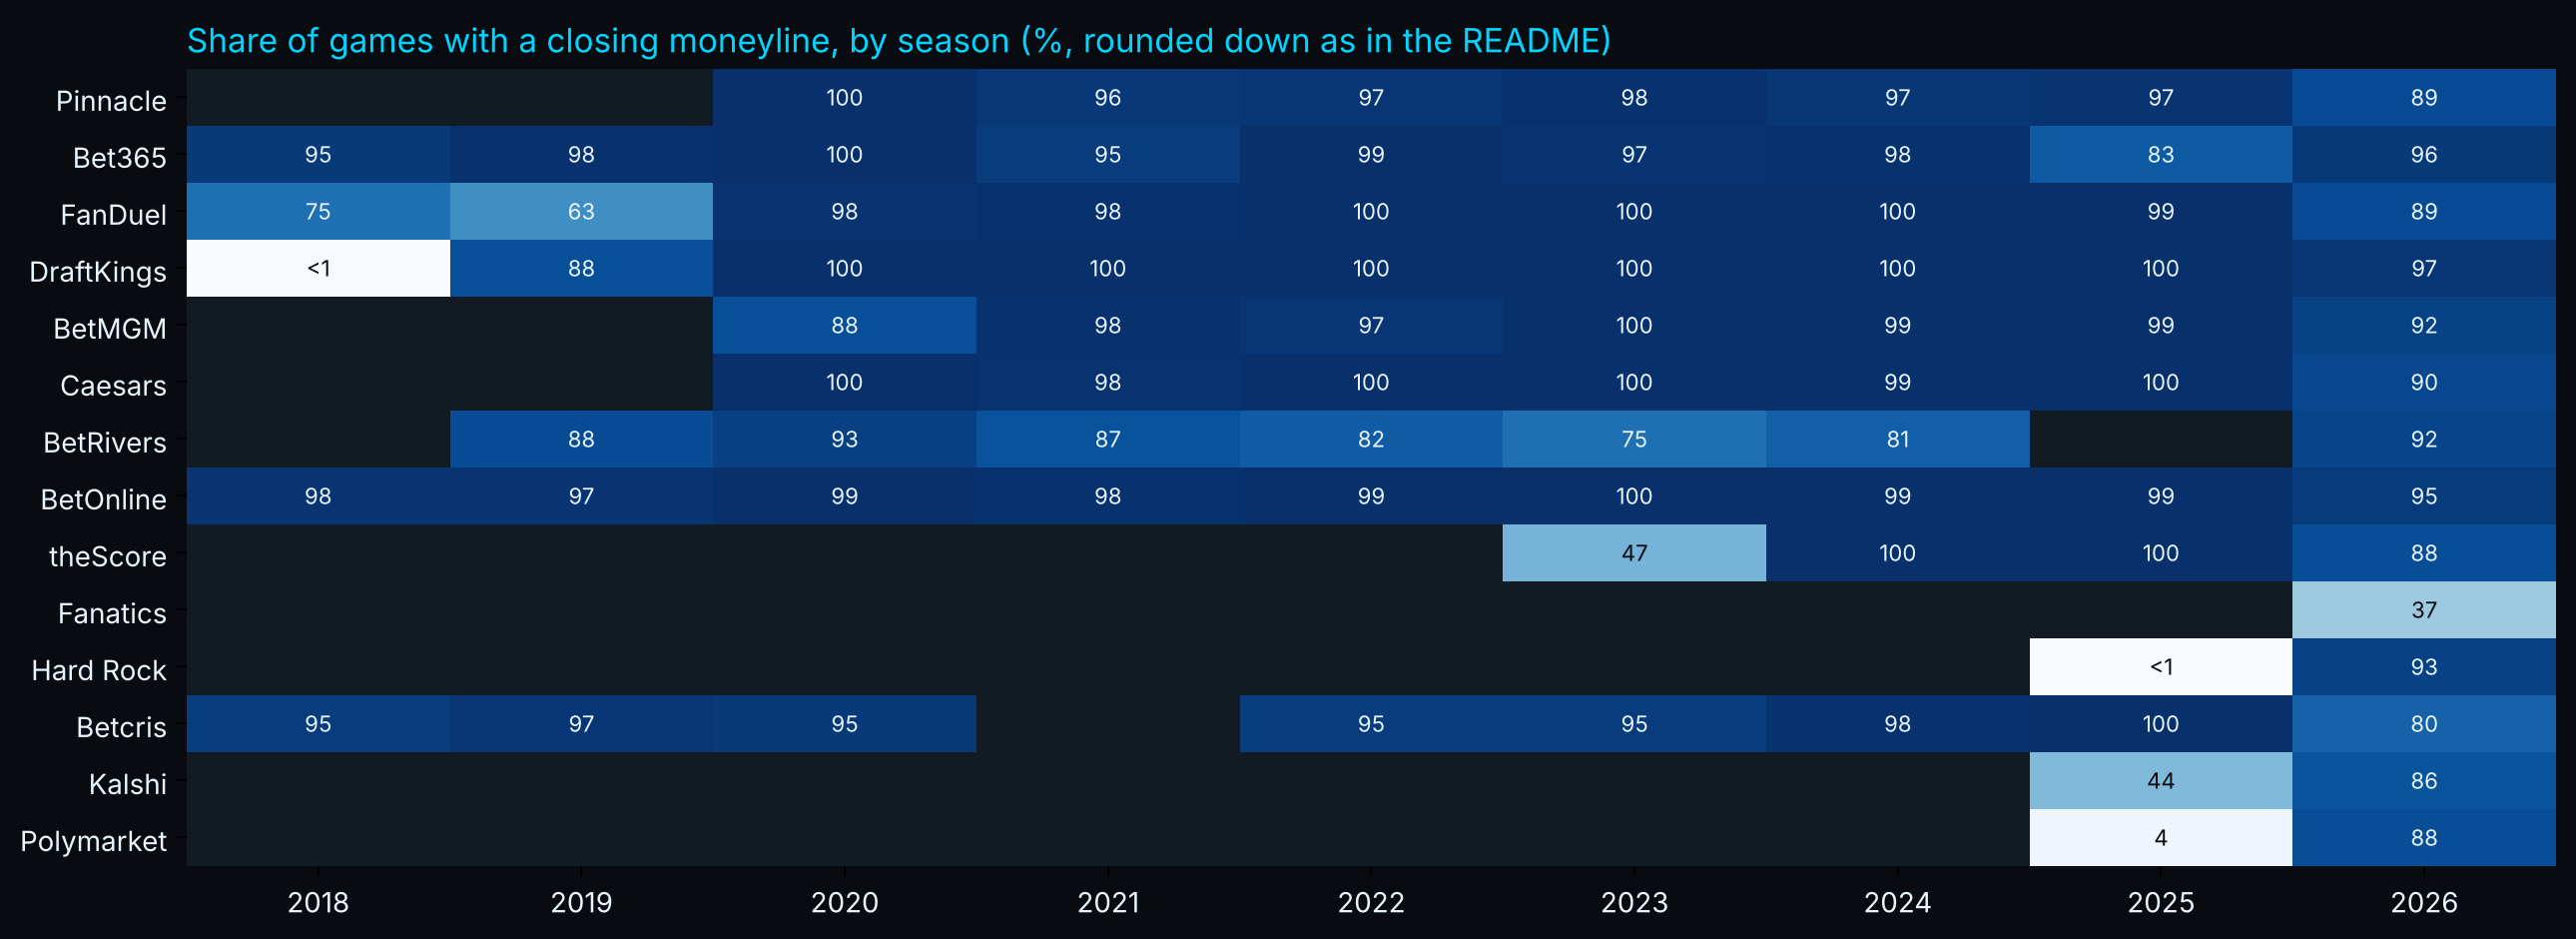

In [10]:
seasons = sorted(RAW["Season"].unique())
cov = pd.DataFrame({s: [100 * has(f"{s}_ML_Home_Close")[RAW["Season"] == se].mean() for se in seasons] for s in SOURCES}, index=seasons)
fig, ax = plt.subplots(figsize=(13, 4.8), facecolor="#080c10")
ax.set_facecolor("#080c10")
cmap = plt.get_cmap("Blues").copy(); cmap.set_bad("#121a22")
ax.imshow(np.ma.masked_equal(cov.T.values, 0), aspect="auto", cmap=cmap, vmin=0, vmax=100)
ax.set_xticks(range(len(cov.index)), cov.index, color="#e8f4ff")
ax.set_yticks(range(len(SOURCES)), [s.replace("HardRock", "Hard Rock") for s in SOURCES], color="#e8f4ff")
for i in range(len(SOURCES)):
    for j in range(len(cov.index)):
        v = cov.T.values[i, j]
        ax.text(j, i, "" if v == 0 else ("<1" if v < 1 else str(int(v))), ha="center", va="center", fontsize=8,
                color="#e8f4ff" if v > 55 else "#080c10")
ax.set_title("Share of games with a closing moneyline, by season (%, rounded down as in the README)", color="#00d4ff", loc="left")
for sp in ax.spines.values(): sp.set_visible(False)
plt.tight_layout(); plt.show()

## Result

In [11]:
n_ok = sum(ok for _, ok in RESULTS)
print(f"{n_ok} PASS / {len(RESULTS) - n_ok} FAIL out of {len(RESULTS)} checks")
assert n_ok == len(RESULTS), [l for l, ok in RESULTS if not ok]

80 PASS / 0 FAIL out of 80 checks


---
🏈 **[→ The full dataset on Gumroad](https://sportsdataolivier.gumroad.com/l/yjnxja?utm_source=github&utm_medium=notebook&utm_campaign=nfl_us&utm_content=notebook_bottom)** · also on [Whop](https://whop.com/oliviersportsdata/nfl-opening-closing-odds-9-us-books-pinnacle-2018-2026/?utm_source=github&utm_medium=notebook&utm_campaign=nfl_us&utm_content=whop_bottom)

Licence: single commercial user. Use the data as you wish, including the models, predictions and products you sell.
Redistribution and resale of the files, or of the raw data in another format, are not permitted.
A question, an invoice or a custom extract: contact@oliviersportsdata.com

*Olivier Sports Data — From Chicken Area 🐔*